# 06 — Market Regime

Rule-based first. HMM/ML can be added later.


In [3]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path


def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")


project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)


Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [4]:
# Cell: Import Market Regime Modules
import importlib

from src.analytics.entropy import build_market_entropy_profile
from src.data.loaders import read_parquet, save_parquet
from src.features.breadth import calculate_market_breadth
from src.models.regime import add_market_regime
from src.reporting.chart_factory import entropy_regime_chart


In [5]:
# Cell: Build Market Regime Frame
features = read_parquet("data/processed/stock_features.parquet")

features["date"] = features["date"].astype("datetime64[ns]")
breadth = calculate_market_breadth(features)
market = add_market_regime(breadth)
market_entropy = build_market_entropy_profile(features, windows=[21, 63, 126], n_bins=24)
market = market.merge(market_entropy, on="date", how="left")
market.shape


(1617, 17)

,date,stock_count,pct_above_ma20,pct_above_ma50,pct_above_ma200,advance_count,decline_count,advance_decline_ratio,up_down_volume_ratio,market_regime,market_proxy_return_1d,advance_ratio,market_entropy_21d,market_entropy_63d,market_entropy_126d,market_entropy_regime,market_entropy_shift
1597,2026-06-02,449,0.278396,0.325167,0.267261,110,261,0.421456,0.187348,Risk-off,-0.005101,0.244989,0.854124,0.588860,0.636289,Chaotic,Stable
1598,2026-06-03,451,0.301552,0.334812,0.268293,216,146,1.479452,4.030314,Risk-off,0.002930,0.478936,0.833352,0.587643,0.632789,Chaotic,Stable
1599,2026-06-04,448,0.292411,0.314732,0.272321,161,191,0.842932,1.491225,Risk-off,-0.001721,0.359375,0.846284,0.580528,0.627925,Chaotic,Stable
1600,2026-06-05,450,0.286667,0.304444,0.266667,112,245,0.457143,0.486166,Risk-off,-0.003114,0.248889,0.846284,0.580528,0.629225,Chaotic,Stable
1601,2026-06-08,458,0.209607,0.255459,0.244541,82,288,0.284722,0.167248,Risk-off,-0.007921,0.179039,0.796900,0.580528,0.632498,Chaotic,Stable
1602,2026-06-09,457,0.242888,0.251641,0.256018,202,149,1.355705,4.604578,Risk-off,0.002848,0.442013,0.768288,0.702252,0.632190,Chaotic,Stable
1603,2026-06-10,454,0.301762,0.279736,0.270925,242,120,2.016667,4.353990,Risk-off,0.005863,0.533040,0.796900,0.709176,0.634934,Chaotic,Stable
1604,2026-06-11,456,0.324561,0.293860,0.245614,143,208,0.687500,0.370226,Risk-off,-0.000568,0.313596,0.796900,0.691183,0.632498,Chaotic,Stable
1605,2026-06-12,463,0.317495,0.291577,0.248380,137,210,0.652381,1.496807,Risk-off,-0.001641,0.295896,0.796900,0.691183,0.629753,Chaotic,Stable
1606,2026-06-15,470,0.412766,0.308511,0.276596,241,116,2.077586,5.111492,Risk-off,0.005919,0.512766,0.796900,0.702252,0.632498,Chaotic,Stable


,date,market_regime,market_entropy_21d,market_entropy_63d,market_entropy_regime,market_entropy_shift,advance_ratio
1616,2026-06-29,Risk-off,0.80474,0.704219,Chaotic,Stable,0.490826


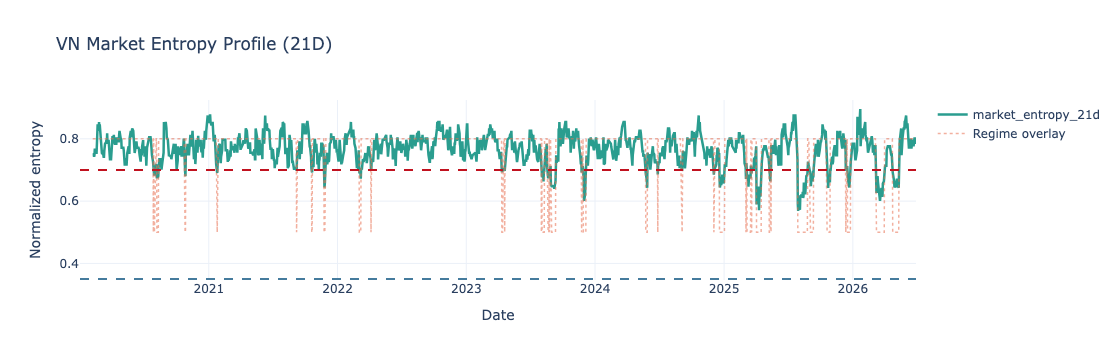

In [6]:
# Cell: Inspect Market Regime Outputs
display(market.tail(20))
latest_market = market.sort_values("date").tail(1)
display(latest_market[[col for col in ["date", "market_regime", "market_entropy_21d", "market_entropy_63d", "market_entropy_regime", "market_entropy_shift", "advance_ratio"] if col in latest_market.columns]])
display(entropy_regime_chart(market, entropy_col="market_entropy_21d", regime_col="market_entropy_regime", title="VN Market Entropy Profile (21D)"))


In [7]:
# Cell: Save Market Regime Outputs
save_parquet(market, "data/processed/market_features.parquet")
display(market["market_regime"].value_counts(dropna=False))
market["market_entropy_regime"].value_counts(dropna=False) if "market_entropy_regime" in market.columns else None


market_regime
Risk-off    1223
Neutral      394
Name: count, dtype: int64

market_entropy_regime
Chaotic         1442
Transitional     154
Unknown           21
Name: count, dtype: int64